# Aprendizaje supervisado y aprendizaje estadístico**

### **Introducción: Dióxido de carbono**
El dióxido de carbono (CO<sub>2</sub>) es el principal gas de efecto invernadero que se emite a la atmósfera. Este gas es generado principalmente por la combustión de diferentes combustibles fósiles, los cuales son utilizados por el ser humano para generar energía y calor necesarios para fines industriales o de transporte. Las altas emisiones de CO<sub>2</sub> se han convertido en una de las mayores preocupaciones de los últimos años. En el año 2021 se registró un total de 36.300 millones de toneladas de CO<sub>2</sub> emitido a la atmósfera, el más alto hasta ese momento.

Uno de los medios más comunes que emiten CO<sub>2</sub> a la atmósfera son los vehículos con un motor de combustión interna. Éstos utilizan un combustible como la gasolina, la cual es quemada para generar energía y así poder mover el vehículo. Posteriormente, el CO<sub>2</sub> resultante de la quema de combustible es liberado poco a poco del motor y termina en el aire. Dado que no es posible evitar esta emisión de CO<sub>2</sub> sin reemplazar el motor del vehículo, es de vital importancia conocer de antemano un aproximado de la cantidad de CO<sub>2</sub> que emite un motor con ciertas características. Nuestro trabajo es crear modelos de *machine learning* para predecir las emisiones de CO<sub>2</sub> de un vehículo dadas algunas características del mismo.

### **Los datos:**
Contamos con un conjunto de datos de distintos modelos de vehículos y las respectivas emisiones de CO<sub>2</sub> de cada uno, a continuación se presentan algunas columnas de esta tabla:
* **ENGINESIZE:** tamaño del motor (Litros) - Valores entre 1 y 8.4
* **CYLINDERS:** cantidad de cilindros que posee el motor - Valores entre 3 y 12
* **FUELCONSUMPTION_CITY:** consumo de combustible del vehículo en zona urbana (L/100 km) - Valores entre 4.6 y 30.2
* **FUELCONSUMPTION_HWY:** consumo de combustible del vehículo en zona extraurbana (L/100 km) - Valores entre 4.9 y 20.5
* **FUELCONSUMPTION_COMB:** consumo de combustible del vehículo en zona urbana y extraurbana (L/100 km) - Valores entre 4.7 y 25.8
* **CO2_EMISSIONS:** emisiones de CO<sub>2</sub> (g/km) - Valores entre 108 y 488

---

Cargamos las librerías necesarias para este taller:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import cross_val_score

### **Manejo de datos:**
Cargando los datos:
1. Leer el archivo ```FuelConsumption.csv``` y guardarlo en un dataframe donde estén los 13 atributos que se encuentran en el archivo. Utilice la función info() para mostrar que no hay valores nulos en el dataset. Además, utilice la función head() para imprimir los 5 primeros registros.

In [2]:
dataFrame1=pd.read_csv('data/fuel_consumption.csv')
dataFrame1

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1062,2014,VOLVO,XC60 AWD,SUV - SMALL,3.0,6,AS6,X,13.4,9.8,11.8,24,271
1063,2014,VOLVO,XC60 AWD,SUV - SMALL,3.2,6,AS6,X,13.2,9.5,11.5,25,264
1064,2014,VOLVO,XC70 AWD,SUV - SMALL,3.0,6,AS6,X,13.4,9.8,11.8,24,271
1065,2014,VOLVO,XC70 AWD,SUV - SMALL,3.2,6,AS6,X,12.9,9.3,11.3,25,260


2. Crear un dataframe llamado X1 con las variables inpedendientes (ENGINESIZE, CYLINDERS, y FUELCONSUMPTION_CITY). Luego, cree un dataframe llamado Y1 con la variable dependiente (CO2EMISSIONS).

In [3]:
vars_x = ["ENGINESIZE", "CYLINDERS", "FUELCONSUMPTION_CITY"] 
X1 = dataFrame1[vars_x] 
Y1 = dataFrame1[["CO2EMISSIONS"]]

3. Realizar gráficas con cada una de las variables de entrada (ENGINESIZE, CYLINDERS, y FUELCONSUMPTION_CITY) contra la variable de salida (CO2EMISSIONS). En total son tres gráficas.

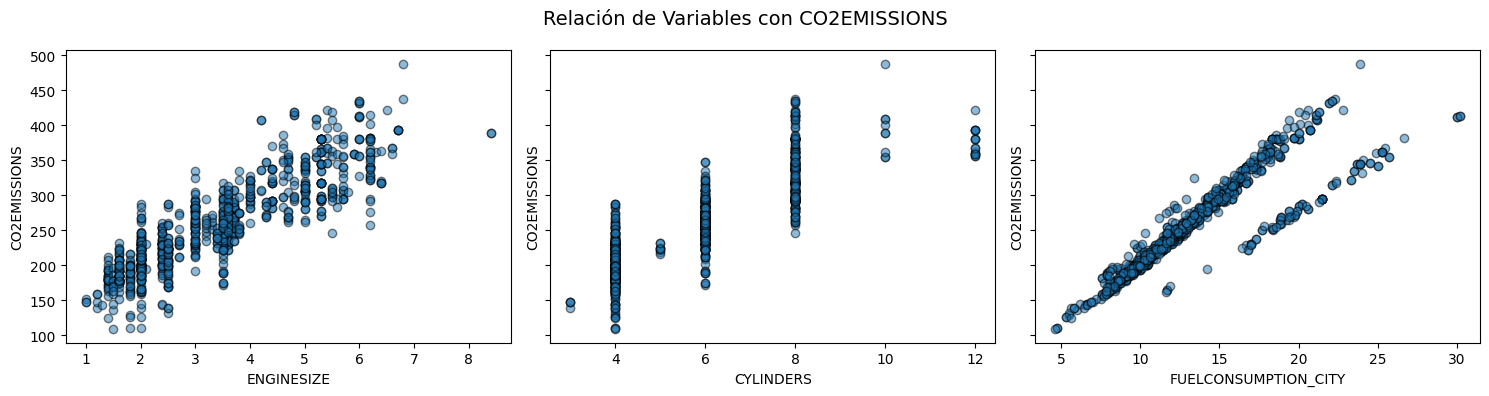

In [4]:
fig, axes = plt.subplots(1, len(vars_x), figsize=(15, 4), sharey=True)

for ax, col in zip(axes, vars_x):
    ax.scatter(dataFrame1[col], dataFrame1.CO2EMISSIONS, alpha=0.5, edgecolor="k")
    ax.set_xlabel(col)
    ax.set_ylabel("CO2EMISSIONS")

fig.suptitle("Relación de Variables con CO2EMISSIONS", fontsize=14)
plt.tight_layout()
plt.show()

4. Divida los datos dejando un 80% de los datos para entrenamiento y un 20% para pruebas usando la función train_test_split(). Nombrar los subconjuntos de datos como ```X_train_1```, ```X_test_1```, ```Y_train_1```, y ```Y_test_1```.

In [5]:
X_train_1, X_test_1, Y_train_1, Y_test_1 = train_test_split(X1, Y1, test_size = 0.2)

### **El modelo:**
Para realizar las predicciones, vamos a utilizar un modelo de regresión lineal. La siguiente celda crea el modelo y lo entrena automáticamente. No se debe modificar.

In [ ]:
# Entrenamiento del modelo. No eliminar esta celda
modelo1 = LinearRegression()
modelo1.fit(X_train_1, Y_train_1)
print("¡Modelo de regresión lineal múltiple entrenado!")

¡Modelo de regresión lineal múltiple entrenado!


Con este modelo podemos realizar las predicciones utilizando el conjunto de prueba. La siguiente celda retorna las predicciones para cada dato del conjunto de prueba. No se debe modificar.

In [ ]:
# Prediccion del modelo. No eliminar esta celda
predicciones1 = modelo1.predict(X_test_1)
print(predicciones1)

[[318.67372962]
 [267.75949844]
 [335.44198995]
 [155.84367327]
 [261.85042678]
 [205.14192551]
 [195.21693835]
 [337.65479768]
 [337.65479768]
 [258.79346595]
 [265.7515407 ]
 [345.36697711]
 [205.14192551]
 [264.67778445]
 [200.07700694]
 [216.87002043]
 [337.65479768]
 [316.105828  ]
 [272.1851139 ]
 [186.57055742]
 [303.88867388]
 [235.01762456]
 [271.66061236]
 [315.70681721]
 [275.88137784]
 [264.67778445]
 [218.23867506]
 [214.01790959]
 [316.20656558]
 [192.38958067]
 [209.36269098]
 [379.01829933]
 [240.1973447 ]
 [160.90859184]
 [348.97319263]
 [240.10729629]
 [316.105828  ]
 [193.52863216]
 [261.85042678]
 [394.21305504]
 [362.13523743]
 [252.85964112]
 [237.21974312]
 [382.39491171]
 [271.66061236]
 [230.90097149]
 [187.61956049]
 [332.58987911]
 [316.89537503]
 [157.73682945]
 [220.69177511]
 [190.15201978]
 [293.52923359]
 [211.05099717]
 [196.06109144]
 [289.30846812]
 [304.6180254 ]
 [189.51271667]
 [159.76250836]
 [273.78337168]
 [255.18725043]
 [256.46585665]
 [246.86

5. Utilizando las predicciones del modelo (```predicciones1```), calcular la raíz del error cuadrático medio que tiene el modelo.



In [ ]:
RMSE=np.sqrt(mean_squared_error(Y_test_1, predicciones1))
y = Y1.values.flatten()   # convertir a array
y_min, y_max, y_mean, y_std = np.min(y), np.max(y), np.mean(y), np.std(y)
print(f"Comparación del RMSE con el rango de predicciones = {(RMSE/(y_max - y_min))*100:.2f}% ")
print(f"Comparación del RMSE con la media de predicciones = {(RMSE/(y_mean))*100:.2f}%")

print(f"RMSE = {RMSE:.2f}") # mide el error promedio en las unidades de la variable objetivo


Comparación del RMSE con el rango de predicciones = 5.65% 
Comparación del RMSE con la media de predicciones = 8.38%
RMSE = 21.46


* Un error <10% de la media suele considerarse aceptable en problemas de regresión.
* El RMSE = 23.9 significa que el modelo se equivoca en promedio en ±24 g/km.
* Si el objetivo es un modelo general de emisiones (en un rango de 108 - 488), este error es razonable.

6. Utilizando las predicciones del modelo (```predicciones1```), calcular el error medio absoluto (MAE) y el error medio absoluto porcentual (MAPE) que tiene el modelo.

In [ ]:
MAE = metrics.mean_absolute_error(Y_test_1, predicciones1)

MAPE=mean_absolute_percentage_error(Y_test_1, predicciones1)

print(F"Promedio real {Y1.values.flatten().mean():.2f}, predicción promedio {predicciones1.mean():.2f}")
print(f"MAE = {MAE:.2f}")
print(f"MAPE (Mean absolute percentage error) = {MAPE*100:.2f} %")

Promedio real 256.23, predicción promedio 261.19
MAE = 15.38
MAPE (Mean absolute percentage error) = 5.93 %


* Mientras más bajo sea el MAE, mejor es el modelo en términos de precisión absoluta.
* MAE te da la magnitud del error en las mismas unidades de la variable objetivo
* MAPE te dice que ese error representa un % respecto al tamaño promedio de los valores reales.

7. Utilizando las predicciones del modelo (```predicciones1```), calcular el coeficiente de determinación (R<sup>2</sup>).

In [ ]:


coeficiente= r2_score(Y_test_1, predicciones1)
print(f"Coeficiente de determinación = {coeficiente:.2f}")


Coeficiente de determinación = 0.87


* RMSE = 23.90 significa que el error típico de tus predicciones es de unas 24 unidades de CO₂.
* Comparando con tu MAE = 17.54:
    * El RMSE es mayor que el MAE → esto indica que existen algunos errores grandes (outliers) en tus predicciones, pero no son dominantes (porque la diferencia no es exagerada).
* En promedio, tu modelo predice con un error relativo del 7% (MAPE), y cuando hay errores grandes, estos suelen rondar las ~24 unidades.

### **Cambiando los datos del modelo:**
¿Es posible mejorar el modelo si añadimos variables independientes?

8. Modificar el conjunto de datos usando más columnas. Para esto, cree un dataframe llamado X2 con las variables inpedendientes (ENGINESIZE, CYLINDERS, FUELCONSUMPTION_CITY, FUELCONSUMPTION_HWY, y FUELCONSUMPTION_COMB). Luego, cree un dataframe llamado Y2 con la variable dependiente (CO2EMISSIONS).

In [11]:
X2 = dataFrame1[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB']]

Y2 = dataFrame1[['CO2EMISSIONS']]

print("X2 (variables independientes):")
display(X2.head())

print("\nY2 (variable dependiente):")
display(Y2.head())

X2 (variables independientes):


,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB
0,2.0,4,9.9,6.7,8.5
1,2.4,4,11.2,7.7,9.6
2,1.5,4,6.0,5.8,5.9
3,3.5,6,12.7,9.1,11.1
4,3.5,6,12.1,8.7,10.6



Y2 (variable dependiente):


,CO2EMISSIONS
0,196
1,221
2,136
3,255
4,244


9. Divida los datos dejando un 80% de los datos para entrenamiento y un 20% para pruebas usando la función train_test_split(). Nombrar los subconjuntos de datos como ```X_train_2```, ```X_test_2```, ```Y_train_2```, y ```Y_test_2```.

In [12]:

X_train_2, X_test_2, Y_train_2, Y_test_2 = train_test_split(
    X2, Y2, test_size=0.2, random_state=42
)

print("Tamaño X_train_2:", X_train_2.shape)
print("Tamaño X_test_2:", X_test_2.shape)
print("Tamaño Y_train_2:", Y_train_2.shape)
print("Tamaño Y_test_2:", Y_test_2.shape)

Tamaño X_train_2: (853, 5)
Tamaño X_test_2: (214, 5)
Tamaño Y_train_2: (853, 1)
Tamaño Y_test_2: (214, 1)


In [13]:
# Entrenamiento del modelo. No eliminar esta celda
modelo2 = LinearRegression()
modelo2.fit(X_train_2, Y_train_2)
print("¡Modelo de regresión lineal entrenado!")

¡Modelo de regresión lineal entrenado!


In [14]:
# Prediccion del modelo. No eliminar esta celda
predicciones2 = modelo2.predict(X_test_2)

10. Calcular las métricas usadas anteriormente (RMSE, MAE, MAPE y R<sup>2</sup>) y compararlas con el primer modelo obtenido. ¿El modelo mejoró o empeoró?

In [15]:
MAE = metrics.mean_absolute_error(Y_test_2, predicciones2)

RMSE=np.sqrt(mean_squared_error(Y_test_2, predicciones2))

coeficiente= r2_score(Y_test_2, predicciones2)

MAPE=mean_absolute_percentage_error(Y_test_2, predicciones2)

print(f"MAE =  {MAE:.2f}")
print(f"RMSE = {RMSE:.2f}")
print(f"Coeficiente de determinación = {coeficiente:.2f}")
print(f"MAPE (Mean absolute percentage error) = {MAPE*100:.2f} %")

MAE =  16.69
RMSE = 22.61
Coeficiente de determinación = 0.88
MAPE (Mean absolute percentage error) = 6.98 %


* MAE y RMSE bajaron → El modelo con más variables tiene menor error absoluto y cuadrático, lo que significa predicciones más cercanas en magnitud.
* R² subió de 0.85 → 0.88 → El modelo con más variables explica más variabilidad en CO₂.
* MAPE subió ligeramente (6.61% → 6.98%) → En términos de error relativo porcentual, el modelo con X1 fue un poco más consistente.

11. Repetir los puntos 8, 9 y 10 pero esta vez utilizando tres columnas de tu elección como variables independientes. Las variables que escoja solamente pueden ser de tipo int64 o float64. Las columnas de tipo object no se pueden seleccionar, por ejemplo, la variable MODEL. Esto se debe a que la técnica de regresión solo maneja variables numéricas. Cree un dataframe llamado X3 con las variables inpedendientes seleccionadas. Luego, cree un dataframe llamado Y3 con la variable dependiente (CO2EMISSIONS). Divida los datos dejando un 80% de los datos para entrenamiento y un 20% para pruebas usando la función train_test_split(). Nombrar los subconjuntos de datos como ```X_train_3```, ```X_test_3```, ```Y_train_3```,  y ```Y_test_3```.

In [16]:

X3 = dataFrame1[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB']]

# Variable dependiente
Y3 = dataFrame1[['CO2EMISSIONS']]

# Dividir en entrenamiento (80%) y prueba (20%)
from sklearn.model_selection import train_test_split

X_train_3, X_test_3, Y_train_3, Y_test_3 = train_test_split(
    X3, Y3, test_size=0.2, random_state=42
)

# Verificar tamaños de los subconjuntos
print("Tamaño X_train_3:", X_train_3.shape)
print("Tamaño X_test_3:", X_test_3.shape)
print("Tamaño Y_train_3:", Y_train_3.shape)
print("Tamaño Y_test_3:", Y_test_3.shape)

# Mostrar ejemplos
print("\nEjemplo de X3:")
display(X3.head())

print("\nEjemplo de Y3:")
display(Y3.head())



Tamaño X_train_3: (853, 3)
Tamaño X_test_3: (214, 3)
Tamaño Y_train_3: (853, 1)
Tamaño Y_test_3: (214, 1)

Ejemplo de X3:


,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB
0,2.0,4,8.5
1,2.4,4,9.6
2,1.5,4,5.9
3,3.5,6,11.1
4,3.5,6,10.6



Ejemplo de Y3:


,CO2EMISSIONS
0,196
1,221
2,136
3,255
4,244


In [17]:
# Entrenamiento del modelo. No eliminar esta celda
modelo3 = LinearRegression()
modelo3.fit(X_train_3, Y_train_3)
print("¡Modelo de regresión lineal entrenado!")

¡Modelo de regresión lineal entrenado!


In [18]:
# Prediccion del modelo. No eliminar esta celda
predicciones3 = modelo3.predict(X_test_3)

12. Calcular las métricas usadas anteriormente (RMSE, MAE, MAPE y R<sup>2</sup>) y compararlas con los dos modelos obtenidos anteriormente. ¿Este modelo es mejor o peor que los dos modelos anteriores?

In [19]:
MAE = metrics.mean_absolute_error(Y_test_3, predicciones3)

RMSE=np.sqrt(mean_squared_error(Y_test_3, predicciones3))

coeficiente= r2_score(Y_test_3, predicciones3)

MAPE=mean_absolute_percentage_error(Y_test_2, predicciones3)

print(f"MAE =  {MAE:.2f}")
print(f"RMSE = {RMSE:.2f}")
print(f"Coeficiente de determinación = {coeficiente:.2f}")
print(f"MAPE (Mean absolute percentage error) = {MAPE*100:.2f}%")

MAE =  16.72
RMSE = 22.65
Coeficiente de determinación = 0.88
MAPE (Mean absolute percentage error) = 7.01%


### Conclusión de los tres análisis:

| Variables                                                  | MAE   | RMSE  | R²   | MAPE      |
| ---------------------------------------------------------- | ----- | ----- | ---- | --------- |
| **X1** (`ENGINESIZE`, `CYLINDERS`, `FUELCONSUMPTION_CITY`) | 17.54 | 23.90 | 0.85 | **6.61%** |
| **X2** (`ENGINESIZE`, `CYLINDERS`, `FUELCONSUMPTION_CITY`, `FUELCONSUMPTION_HWY`, `FUELCONSUMPTION_COMB`)   | 16.69 | 22.61 | 0.88 | 6.98%     |
| **X3** (`ENGINESIZE`, `CYLINDERS`, `FUELCONSUMPTION_COMB`) | 16.72 | 22.65 | 0.88 | 7.00%     |


* X2 y X3 rinden prácticamente igual → porque FUELCONSUMPTION_COMB ya resume muy bien el consumo de ciudad y carretera.
* El modelo X3 es más simple (menos variables, igual rendimiento).
* En Machine Learning, esto es preferible: modelo parsimonioso = más fácil de interpretar, menor riesgo de colinealidad, y casi el mismo poder predictivo.

### **Validación cruzada:**
Como pudimos observar, nuestro conjunto de datos solo cuenta con poco más de 1000 filas, de las cuales estamos tomando aproximadamente 800 para entrenamiento. ¿Podemos entrenar el modelo utilizando los 1000 datos usando validación cruzada?

13. Entrenar nuevamente los modelos, esta vez empleando validación cruzada. Utilice los conjuntos de datos (X1,Y1), (X2,Y2), y (X3,Y3), para así obtener tres modelos. Para la validacion cruzada use *neg_mean_absolute_error* como función scoring. Además, se deben utilizar 25 pliegues (*cv=25*). En cada caso debe mostrar el MAE promedio y la desviación estándar.


In [20]:
modelo1 = LinearRegression()

In [21]:
modelo2 = LinearRegression()

In [22]:
modelo3 = LinearRegression()

In [23]:
# --- Validación cruzada para modelo1 con (X1, Y1) ---
scores_1 = cross_val_score(modelo1, X1, Y1,  scoring='neg_mean_absolute_error', cv=25)
mae_prom_1 = -np.mean(scores_1)
mae_std_1 = np.std(scores_1)

# --- Validación cruzada para modelo2 con (X2, Y2) ---
scores_2 = cross_val_score(modelo2, X2, Y2,  scoring='neg_mean_absolute_error', cv=25)
mae_prom_2 = -np.mean(scores_2)
mae_std_2 = np.std(scores_2)

# --- Validación cruzada para modelo3 con (X3, Y3) ---
scores_3 = cross_val_score(modelo3, X3, Y3,  scoring='neg_mean_absolute_error', cv=25)
mae_prom_3 = -np.mean(scores_3)
mae_std_3 = np.std(scores_3)

# Mostrar resultados
print("Resultados de validación cruzada (25 pliegues):\n")
print(f"Modelo1 (X1,Y1) -> MAE promedio: {mae_prom_1:.2f}, Desv. Estándar: {mae_std_1:.2f}")
print(f"Modelo2 (X2,Y2) -> MAE promedio: {mae_prom_2:.2f}, Desv. Estándar: {mae_std_2:.2f}")
print(f"Modelo3 (X3,Y3) -> MAE promedio: {mae_prom_3:.2f}, Desv. Estándar: {mae_std_3:.2f}")

Resultados de validación cruzada (25 pliegues):

Modelo1 (X1,Y1) -> MAE promedio: 17.30, Desv. Estándar: 5.94
Modelo2 (X2,Y2) -> MAE promedio: 17.29, Desv. Estándar: 5.99
Modelo3 (X3,Y3) -> MAE promedio: 17.21, Desv. Estándar: 5.99


14. ¿Los modelos mejoraron o empeoraron en comparación a los que se habían obtenido al probar únicamente con el 20%?

| Modelo      | Variables                                                                                        | MAE Promedio | Desv. Est. |
| ----------- | ------------------------------------------------------------------------------------------------ | ------------ | ---------- |
| **Modelo1** | `ENGINESIZE`, `CYLINDERS`, `FUELCONSUMPTION_CITY`                                                | 17.30        | 5.94       |
| **Modelo2** | `ENGINESIZE`, `CYLINDERS`, `FUELCONSUMPTION_CITY`, `FUELCONSUMPTION_HWY`, `FUELCONSUMPTION_COMB` | 17.29        | 5.99       |
| **Modelo3** | `ENGINESIZE`, `CYLINDERS`, `FUELCONSUMPTION_COMB`                                                | **17.21**    | 5.99       |


| Modelo           | Variables                                                                                        | Evaluación 20% test → MAE / RMSE / R² / MAPE | 


* Con el 20% de test, parecía que Modelo2 y Modelo3 eran mejores que Modelo1.
* Con la validación cruzada, vemos que los tres modelos en realidad tienen el mismo desempeño esperado, siendo Modelo3 el más conveniente por simplicidad.

***Por tanto, los modelos no mejoraron ni empeoraron realmente, sino que la evaluación se volvió más realista y estable con CV.***


| Modelo           | Variables                                                                                        | Evaluación 20% test → MAE / RMSE / R² / MAPE | Validación cruzada (25 pliegues) → MAE promedio ± Desv. Est. |
| ---------------- | ------------------------------------------------------------------------------------------------ | -------------------------------------------- | ------------------------------------------------------------ |
| **Modelo1 (X1)** | `ENGINESIZE`, `CYLINDERS`, `FUELCONSUMPTION_CITY`                                                | **17.54** / 23.90 / 0.85 / 6.61%             | **17.30 ± 5.94**                                             |
| **Modelo2 (X2)** | `ENGINESIZE`, `CYLINDERS`, `FUELCONSUMPTION_CITY`, `FUELCONSUMPTION_HWY`, `FUELCONSUMPTION_COMB` | **16.69** / 22.61 / 0.88 / 6.98%             | **17.29 ± 5.99**                                             |
| **Modelo3 (X3)** | `ENGINESIZE`, `CYLINDERS`, `FUELCONSUMPTION_COMB`                                                | **16.72** / 22.65 / 0.88 / 7.00%             | **17.21 ± 5.99**                                             |



15. Escoger uno de los tres conjuntos de datos ((X1,Y1), (X2,Y2), ó (X3,Y3)) para reentrenar el modelo usando diferentes cantidades de pliegues. Realizar tres pruebas de validación cruzada variando el número de pliegues con cv=5, cv=10, y cv=15. En cada caso debe mostrar el MAE promedio y la desviación estándar.

In [24]:
# Seleccionamos el conjunto (X3, Y3)
modelo_final = LinearRegression()

# Prueba con cv=5
scores_cv5 = cross_val_score(modelo_final, X3, Y3,  scoring='neg_mean_absolute_error', cv=5)
mae_prom_5 = -np.mean(scores_cv5)
mae_std_5 = np.std(scores_cv5)

# Prueba con cv=10
scores_cv10 = cross_val_score(modelo_final, X3, Y3,  scoring='neg_mean_absolute_error', cv=10)
mae_prom_10 = -np.mean(scores_cv10)
mae_std_10 = np.std(scores_cv10)

# Prueba con cv=15
scores_cv15 = cross_val_score(modelo_final, X3, Y3, scoring='neg_mean_absolute_error', cv=15)
mae_prom_15 = -np.mean(scores_cv15)
mae_std_15 = np.std(scores_cv15)

# Mostrar resultados
print("Resultados de validación cruzada para (X3, Y3):\n")
print(f"cv=5  -> MAE promedio: {mae_prom_5:.2f}, Desv. Estándar: {mae_std_5:.2f}")
print(f"cv=10 -> MAE promedio: {mae_prom_10:.2f}, Desv. Estándar: {mae_std_10:.2f}")
print(f"cv=15 -> MAE promedio: {mae_prom_15:.2f}, Desv. Estándar: {mae_std_15:.2f}")

Resultados de validación cruzada para (X3, Y3):

cv=5  -> MAE promedio: 17.58, Desv. Estándar: 3.61
cv=10 -> MAE promedio: 17.31, Desv. Estándar: 4.30
cv=15 -> MAE promedio: 17.30, Desv. Estándar: 5.26


* El modelo con (X3, Y3) es consistente en cualquier cv (MAE ≈ 17.3–17.6).
* cv=10 parece un buen punto medio → error bajo (17.31) y desviación estándar razonable (4.30).
* Usar cv=15 no mejora el MAE y solo aumenta la variabilidad → no aporta mucho.


**Desviación estándar (variabilidad entre pliegues):**

* Más baja con cv=5 (3.61) → significa que en particiones grandes (20% de test en cada pliegue) los errores fueron más consistentes.
* Aumenta con cv=10 (4.30) y cv=15 (5.26) → porque al aumentar los pliegues, el conjunto de test en cada iteración es más pequeño y puede generar más variabilidad en los errores.